# Исследование возможностей автоэнкодеров для восстановления изображений клеток крови на примере Vanilla Autoencoder (AE). Датасет BloodMNIST

Описание датасета: BloodMNIST

BloodMNIST - часть коллекции MedMNIST, стандартизированного набора медицинских изображений формата 28×28. Датасет содержит 17 092 цветных микроскопических изображения клеток периферической крови, полученных от здоровых доноров без инфекционных, гематологических или онкологических заболеваний. Изображения организованы в 8 морфологических классов клеток крови:

| Индекс | Класс (en) | Класс (рус.) |
|---|---|---|
| 0 | Basophil | Базофил |
| 1 | Eosinophil | Эозинофил |
| 2 | Erythroblast | Эритробласт |
| 3 | Immature Granulocyte | Незрелый гранулоцит |
| 4 | Lymphocyte | Лимфоцит |
| 5 | Monocyte | Моноцит |
| 6 | Neutrophil | Нейтрофил |
| 7 | Platelet | Тромбоцит |


Исходные изображения имели разрешение 3×360×363 пикселя, были центрально обрезаны до 3×200×200 и затем приведены к **3×28×28** — стандартному формату MedMNIST. В отличие от Fashion-MNIST, здесь **три цветовых канала (RGB)**, что важно для архитектуры: входной и выходной слои модели должны принимать и выдавать `3*28*28` значений.

**Разбиение датасета** (фиксированное в MedMNIST, не перемешивается):
- **Train:** 11 959 изображений
- **Val:** 1 712 изображений
- **Test:** 3 421 изображение

Такое разбиение позволяет корректно отслеживать переобучение и выбирать гиперпараметры по валидации, не трогая тест до финальной оценки. В коде используется именно это разбиение: `train_ds`, `val_ds`, `test_ds` загружаются отдельно, а `test_loader` применяется только для финальных визуализаций.

**Специфика домена, которую нужно учитывать:**
- Классы визуально похожи (например, нейтрофилы и эозинофилы, моноциты и незрелые гранулоциты), поэтому даже небольшая потеря деталей при реконструкции может быть критична.
- Цвет несёт диагностическую информацию (окраска клеток), поэтому MSE по трём каналам — не идеальная метрика; в перспективе стоит добавить SSIM/PSNR.
- Размер изображений мал (28×28), что ограничивает архитектуру: полносвязный AE справляется с общей формой и цветом, но теряет мелкие текстуры ядра - это ожидаемо и обсуждается в ретроспективе.

**Команда проекта**
- Калиниченко Ирина
- Асанбекова Дэниза
- Хван Маргарита


## 1. Project Charter (устав проекта)

| Поле | Значение |
|---|---|
| **Название** | Vanilla Autoencoder (AE) для восстановления изображений клеток крови (BloodMNIST) |
| **Спонсор / заказчик** | Учебный семинар по глубокому обучению |
| **Проблема** | Медицинские микроскопические изображения часто содержат шум. Нужен компактный способ представления, который восстанавливает сигнал и может использоваться для downstream-задач. |
| **SMART-цель** | К концу семинара получить AE, который восстанавливает изображения BloodMNIST с reconstruction MSE < 0.02 и имеет латентное пространство dim = 32, пригодное для визуализации через PCA/t-SNE. |
| **Входит в scope** | эксперименты с `latent_dim ∈ {2, 8, 32}`; визуализация пар «оригинал / восстановленное»; визуализация латента. |
| **Не входит в scope** | VAE, conditional AE, supervised-классификация клеток, деплой, работа с полноразмерными изображениями (200×200 и выше). |
| **Стейкхолдеры** |Студенты: Асанбекова Дэниза, Калиниченко Ирина, Хван Маргарита (исполнители), преподаватель: Вахромеева Екатерина Александровна (заказчик/приёмка), условный «аналитик медицинских изображений» (конечный пользователь). |
| **Критерий успеха** | Восстановленные изображения визуально близки к оригиналам; латентные кластеры различимы. |
| **Ограничения** | CPU-only или слабый GPU; минимум зависимостей (`torch`, `torchvision`, `medmnist`, `sklearn`). |

---

## 2. WBS (Work Breakdown Structure) и Roadmap

**1. Инициация**

1.1. Постановка цели и ограничений (charter)

1.2. Согласование критериев успеха (MSE, визуальное качество)

**2. Подготовка данных**

2.1. Загрузка BloodMNIST через `medmnist` (train / val / test)

2.2. EDA: примеры по 8 классам, проверка баланса классов, визуализация цветовых каналов

2.3. Нормализация: `ToTensor()` → диапазон [0, 1]


**3. Моделирование**

3.1. Проектирование архитектуры encoder/decoder под RGB-вход (`3*28*28`)

3.2. Реализация AE: forward принимает изображение, возвращает восстановленное и латент

3.3. Цикл обучения: loss = MSE(восстановленное, оригинал), валидация на каждой эпохе

3.4. Сохранение истории обучения (loss, time) для построения графиков

**4. Эксперименты**

4.1. Сравнение `latent_dim ∈ {2, 8, 32}`

4.3. Логирование в таблицу

4.4. Визуализация пар и латентного пространства

**Roadmap (упрощённый Gantt):**

| День | Задача | Owner | Статус |
|---|---|---|---|
| 1 | Charter + WBS | PM / преподаватель | ✅ |
| 1 | Загрузка данных + EDA | Data | ✅ |
| 2 | Baseline AE (dim=32)  | ML | ✅ |
| 2 | Эксперименты с `latent_dim` | ML | ✅ |
| 3 | Визуализации + итоговая таблица | ML / PM | ✅ |
| 3 | Ретроспектива | Все | ✅ |


## 3. Kanban board и Risk register

**Kanban:**

📋 **Backlog**
- Добавить convolutional AE (Conv2d / ConvTranspose2d) - критично для сохранения мелких текстур ядра
- Попробовать VAE как генеративную модель для синтетических клеток
- Сравнить с PCA-baseline: сколько компонент нужно для того же MSE, что у AE
- Добавить per-class MSE и SSIM/PSNR
- Реализовать Denoising AE (добавление гауссова шума) и проверить устойчивость модели

🚧 **In Progress**
- Визуализация латентного пространства через t-SNE для dim=32

✅ **Done**
- Charter
- WBS
- Загрузка BloodMNIST (train / val / test)
- Модель AE (vanilla, полносвязная)
- Скрипт обучения с валидацией

**Risk register:**

| Риск | Вероятность | Влияние | Митигация |
|---|---|---|---|
| Переобучение на train (11 959 изображений) | Средняя | Высокое | Валидация на каждой эпохе |
| `latent_dim=2` слишком мало для 8 классов | Высокая | Среднее | Сравнить с dim=8 и dim=32. |
| Медленное обучение на CPU | Средняя | Среднее | Уменьшить epochs, использовать подвыборку. |
| Плоская визуализация латента | Средняя | Среднее | Проверить, что модель обучилась; использовать t-SNE. |

## 4. Experiment log и Definition of Done

**Experiment log (Столбцы):**
- `latent_dim` — размер латентного пространства (2, 8, 32).
- `final_train_loss` - MSE на тренировочной выборке в конце обучения.
- `final_val_loss` - MSE на валидационной выборке в конце обучения.
- `total_time_s` - суммарное время обучения (в секундах).

**Definition of Done (DoD):**
- Модель обучается без ошибок, `train_loss` и `val_loss` падают.
- На валидации достигнут MSE < 0.02 (для latent_dim = 32).
- Построены пары «оригинал / восстановленное».
- Построено латентное пространство: scatter для `dim=2`, PCA и t-SNE для `dim=32`.
- Заполнена итоговая таблица экспериментов.
- Записаны выводы: что получилось, где модель ошибается.

In [ ]:
import os, time, copy, random
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from sklearn.decomposition import PCA
from sklearn.manifold import TSNE

import torch
import torch.nn as nn
import torch.optim as optim
from torch.utils.data import DataLoader
import torchvision.transforms as transforms

# Импортируем BloodMNIST из medmnist
!pip install medmnist
from medmnist import BloodMNIST, INFO

SEED = 42
random.seed(SEED); np.random.seed(SEED)
torch.manual_seed(SEED)
device = torch.device("cuda" if torch.cuda.is_available() else "cpu")
print("Device:", device, "| Torch:", torch.__version__)

Device: cpu | Torch: 2.14.1+cpu


In [ ]:
#Используем ToTensor, чтобы получить значения в диапазоне [0, 1]
transform = transforms.ToTensor()

#MedMNIST сам скачает данные при download=True
train_ds = BloodMNIST(split='train', download=True, transform=transform)
val_ds   = BloodMNIST(split='val', download=True, transform=transform)
test_ds  = BloodMNIST(split='test', download=True, transform=transform)

BATCH_SIZE = 128
train_loader = DataLoader(train_ds, batch_size=BATCH_SIZE, shuffle=True)
val_loader   = DataLoader(val_ds, batch_size=256, shuffle=False)
test_loader  = DataLoader(test_ds, batch_size=256, shuffle=False)

#Классы BloodMNIST
class_names = ['Basophil', 'Eosinophil', 'Erythroblast', 'Immature Granulocyte',
               'Lymphocyte', 'Monocyte', 'Neutrophil', 'Platelet']
print("Train:", len(train_ds), "| Val:", len(val_ds), "| Test:", len(test_ds))

100%|██████████| 35.5M/35.5M [00:12<00:00, 2.81MB/s]


Train: 11959 | Val: 1712 | Test: 3421


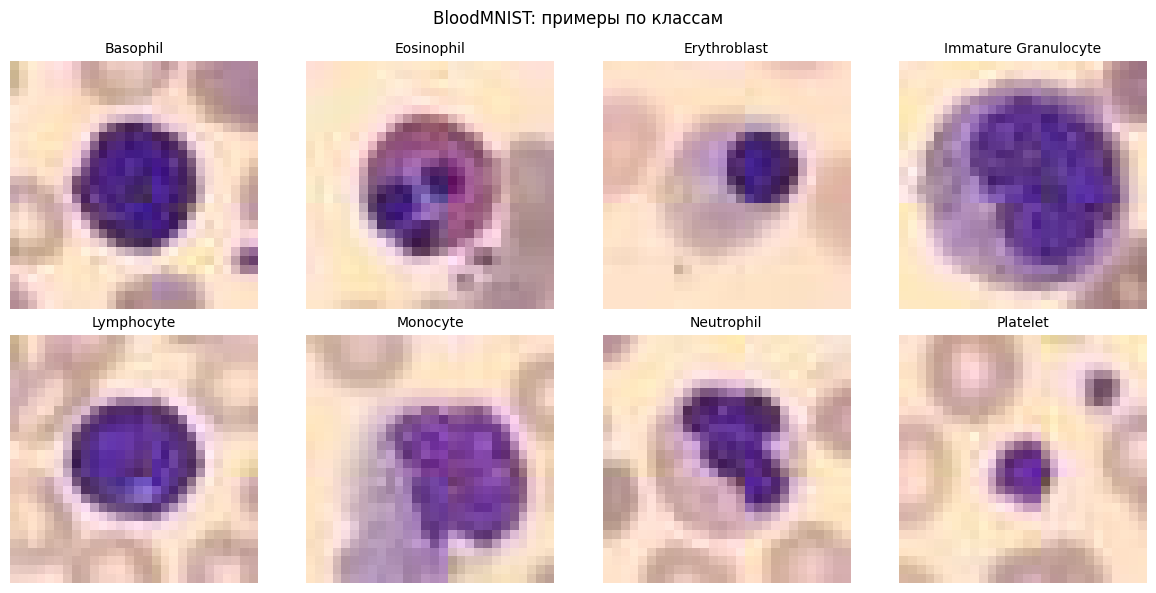

In [ ]:
# EDA: примеры по классам
fig, axes = plt.subplots(2, 4, figsize=(12, 6))
for cls_idx, ax in enumerate(axes.ravel()):
    if cls_idx >= len(class_names): break
    # Находим индексы картинок нужного класса
    idx = np.where(np.array(train_ds.labels) == cls_idx)[0]
    if len(idx) > 0:
        img, _ = train_ds[idx[0]]
        ax.imshow(img.permute(1, 2, 0).numpy())
        ax.set_title(class_names[cls_idx], fontsize=10)
    ax.axis("off")
plt.suptitle("BloodMNIST: примеры по классам")
plt.tight_layout(); plt.show()

In [ ]:
class AE(nn.Module):
    def __init__(self, latent_dim=32):
        super().__init__()
        self.encoder = nn.Sequential(
            nn.Flatten(),
            nn.Linear(3*28*28, 256), nn.ReLU(), #3 канала * 28 * 28
            nn.Linear(256, 64), nn.ReLU(),
            nn.Linear(64, latent_dim),
        )
        self.decoder = nn.Sequential(
            nn.Linear(latent_dim, 64), nn.ReLU(),
            nn.Linear(64, 256), nn.ReLU(),
            nn.Linear(256, 3*28*28), nn.Sigmoid(), #Выход 3 канала
            nn.Unflatten(1, (3, 28, 28)),
        )

    def forward(self, x):
        z = self.encoder(x)
        x_hat = self.decoder(z)
        return x_hat, z

# Проверка размерностей
m = AE(latent_dim=32).to(device)
with torch.no_grad():
    dummy = torch.randn(4, 3, 28, 28).to(device)
    x_hat, z = m(dummy)
print("x_hat:", x_hat.shape, "| z:", z.shape)

x_hat: torch.Size([4, 3, 28, 28]) | z: torch.Size([4, 32])


In [ ]:
@torch.no_grad()
def eval_loss(model, loader, criterion):
    model.eval()
    total = 0.0
    for xb, _ in loader:
        xb = xb.to(device)
        x_hat, _ = model(xb)
        total += criterion(x_hat, xb).item() * xb.size(0)
    return total / len(loader.dataset)

def train_ae(latent_dim=32, epochs=10, lr=1e-3):
    model = AE(latent_dim=latent_dim).to(device)
    optimizer = optim.Adam(model.parameters(), lr=lr)
    criterion = nn.MSELoss()
    history = {"epoch": [], "train_loss": [], "val_loss": [], "time": []}

    for ep in range(epochs):
        t0 = time.time()
        model.train()
        running = 0.0
        for xb, _ in train_loader:
            xb = xb.to(device)
            optimizer.zero_grad()
            x_hat, _ = model(xb)
            loss = criterion(x_hat, xb)
            loss.backward(); optimizer.step()
            running += loss.item() * xb.size(0)

        tr = running / len(train_loader.dataset)
        va = eval_loss(model, val_loader, criterion) # Валидация
        dt = time.time() - t0

        history["epoch"].append(ep + 1)
        history["train_loss"].append(tr)
        history["val_loss"].append(va)
        history["time"].append(dt)

        if (ep + 1) % 2 == 0 or ep == 0:
            print(f"epoch {ep+1:02d}/{epochs} | train {tr:.4f} | val {va:.4f} | {dt:.1f}s")

    return model, history

In [ ]:
#Эксперименты
results = []
models = {}
histories = {}

for ld in [2, 8, 32]:
    print(f"\n===== latent_dim = {ld} =====")
    model, hist = train_ae(latent_dim=ld, epochs=8, lr=1e-3)
    models[ld] = model
    histories[ld] = hist

    results.append({
        "latent_dim": ld,
        "final_train_loss": round(hist["train_loss"][-1], 5),
        "final_val_loss": round(hist["val_loss"][-1], 5),
        "total_time_s": round(sum(hist["time"]), 1),
    })

results_df = pd.DataFrame(results)
print(results_df)


===== latent_dim = 2 =====
epoch 01/8 | train 0.0250 | val 0.0170 | 4.2s
epoch 02/8 | train 0.0143 | val 0.0132 | 4.0s
epoch 04/8 | train 0.0128 | val 0.0125 | 4.0s
epoch 06/8 | train 0.0125 | val 0.0124 | 5.2s
epoch 08/8 | train 0.0124 | val 0.0122 | 5.0s

===== latent_dim = 8 =====
epoch 01/8 | train 0.0248 | val 0.0187 | 5.4s
epoch 02/8 | train 0.0146 | val 0.0128 | 4.0s
epoch 04/8 | train 0.0122 | val 0.0118 | 5.1s
epoch 06/8 | train 0.0114 | val 0.0111 | 4.0s
epoch 08/8 | train 0.0109 | val 0.0107 | 5.1s

===== latent_dim = 32 =====
epoch 01/8 | train 0.0260 | val 0.0194 | 4.4s
epoch 02/8 | train 0.0154 | val 0.0128 | 4.8s
epoch 04/8 | train 0.0123 | val 0.0121 | 4.2s
epoch 06/8 | train 0.0113 | val 0.0110 | 4.0s
epoch 08/8 | train 0.0109 | val 0.0107 | 6.0s
   latent_dim  final_train_loss  final_val_loss  total_time_s
0           2           0.01236         0.01218          35.9
1           8           0.01094         0.01072          37.0
2          32           0.01093        

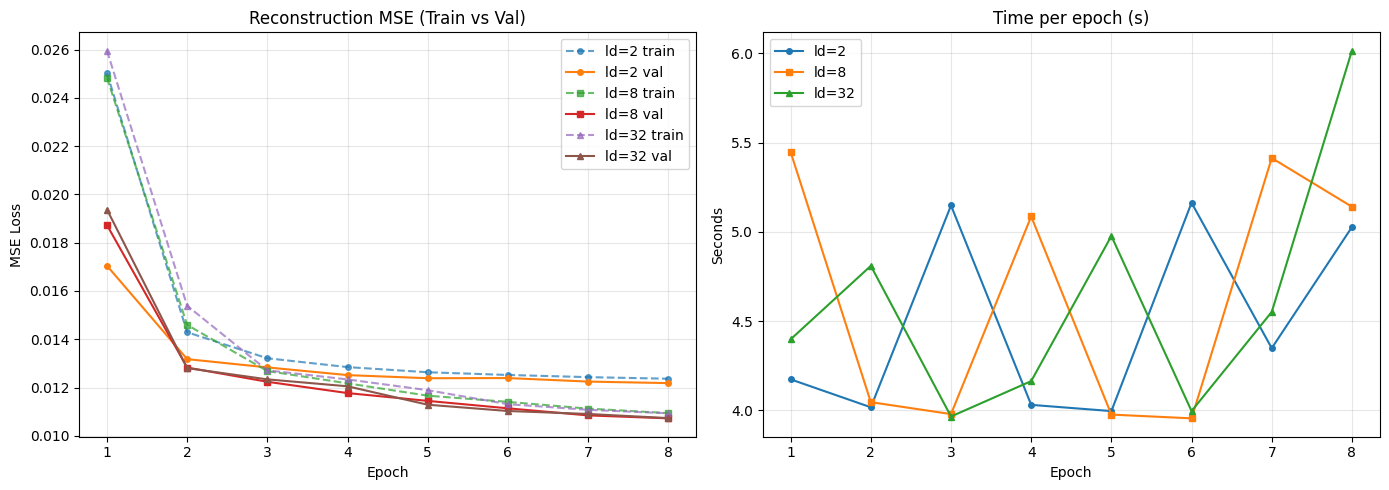

In [ ]:
# Кривые обучения по всем экспериментам
fig, axes = plt.subplots(1, 2, figsize=(14, 5))
markers = {2: 'o', 8: 's', 32: '^'}

for ld, hist in histories.items():
    axes[0].plot(hist["epoch"], hist["train_loss"], linestyle="--", marker=markers[ld],
                 markersize=4, alpha=0.7, label=f"ld={ld} train")
    axes[0].plot(hist["epoch"], hist["val_loss"], linestyle="-", marker=markers[ld],
                 markersize=4, label=f"ld={ld} val")
    axes[1].plot(hist["epoch"], hist["time"], linestyle="-", marker=markers[ld],
                 markersize=4, label=f"ld={ld}")

#Оформление графиков
axes[0].set_title("Reconstruction MSE (Train vs Val)")
axes[0].set_xlabel("Epoch")
axes[0].set_ylabel("MSE Loss")
axes[0].grid(alpha=0.3)
axes[0].legend()

axes[1].set_title("Time per epoch (s)")
axes[1].set_xlabel("Epoch")
axes[1].set_ylabel("Seconds")
axes[1].grid(alpha=0.3)
axes[1].legend()

plt.tight_layout()
plt.show()

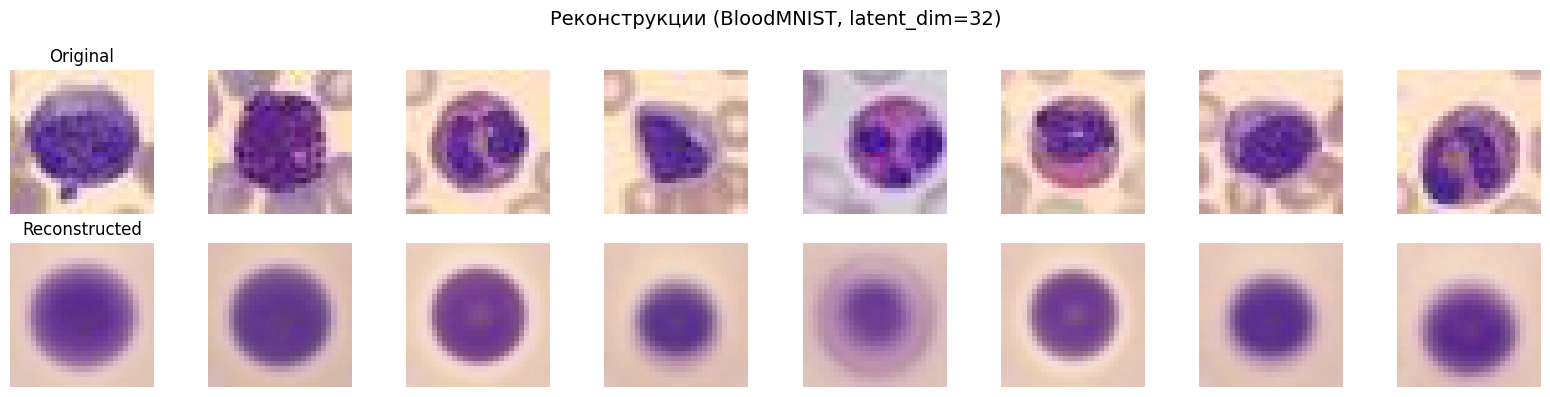

In [ ]:
model = models[32]
model.eval()
x_batch, _ = next(iter(test_loader))
x_batch = x_batch.to(device)
with torch.no_grad():
    x_hat, _ = model(x_batch)

n = 8
fig, axes = plt.subplots(2, n, figsize=(16, 4))
for i in range(n):
    # Оригинал
    axes[0, i].imshow(x_batch[i].cpu().permute(1, 2, 0).numpy())
    axes[0, i].axis("off")
    # Реконструкция
    axes[1, i].imshow(x_hat[i].cpu().permute(1, 2, 0).numpy())
    axes[1, i].axis("off")

axes[0, 0].set_title("Original"); axes[1, 0].set_title("Reconstructed")
plt.suptitle("Реконструкции (BloodMNIST, latent_dim=32)", fontsize=14)
plt.tight_layout(); plt.show()

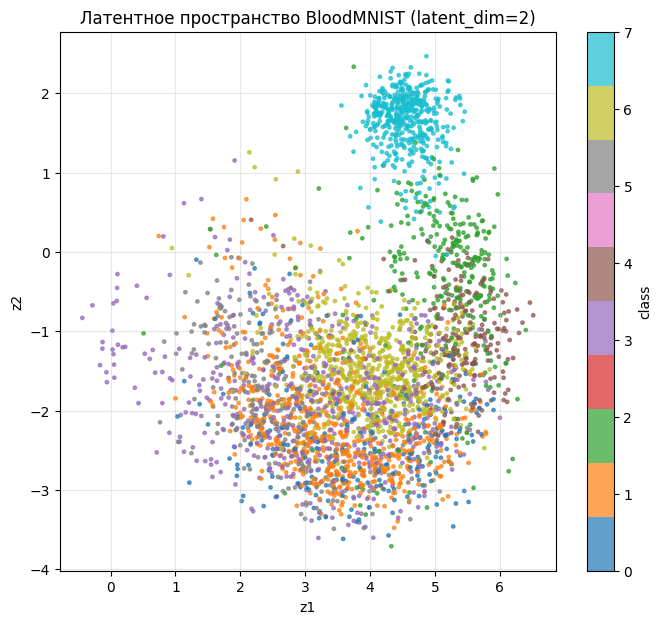

In [ ]:
# Функция для извлечения латентных векторов
@torch.no_grad()
def get_latents(model, loader):
    model.eval()
    Z, Y = [], []
    for xb, yb in loader:
        _, z = model(xb.to(device))
        Z.append(z.cpu().numpy())
        Y.append(yb.flatten().numpy())
    return np.concatenate(Z), np.concatenate(Y)

# Берем модель с latent_dim=2
Z2, Y2 = get_latents(models[2], test_loader)

plt.figure(figsize=(8, 7))
sc = plt.scatter(Z2[:, 0], Z2[:, 1], c=Y2, cmap="tab10", s=6, alpha=0.7)

plt.colorbar(sc, ticks=range(8), label="class")
plt.title("Латентное пространство BloodMNIST (latent_dim=2)")
plt.xlabel("z1"); plt.ylabel("z2")
plt.grid(alpha=0.3); plt.show()

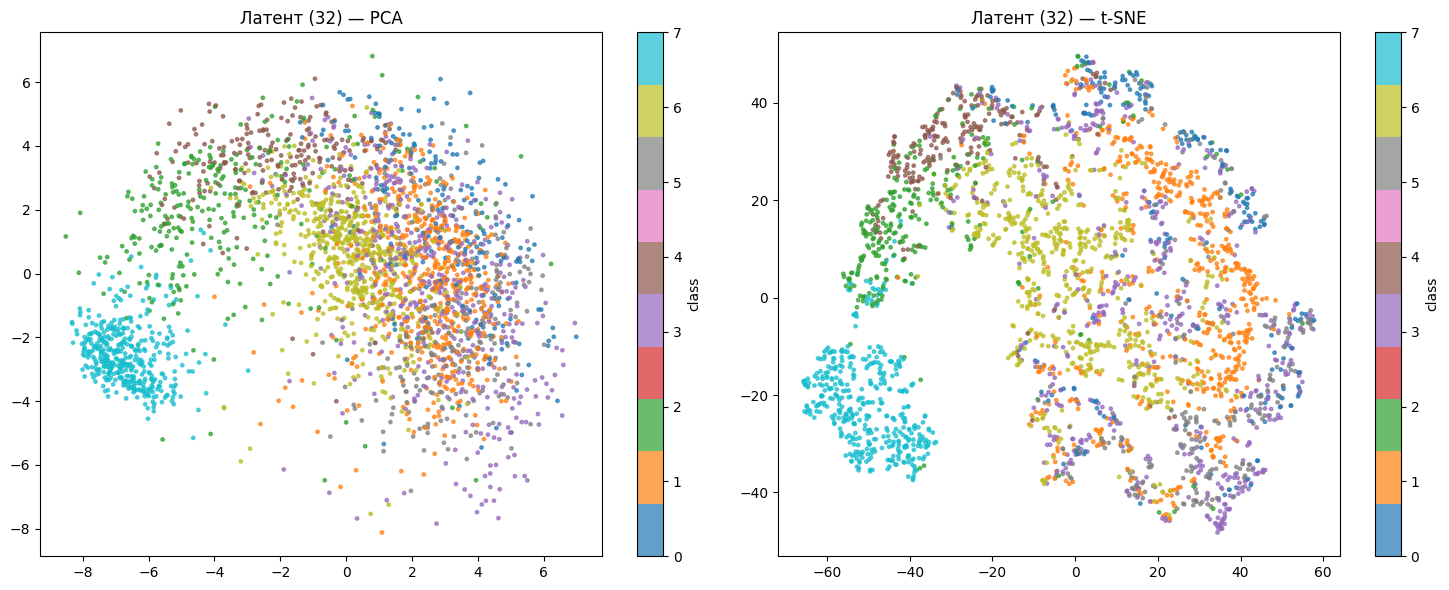

In [ ]:
# Латентное пространство (dim=32) через PCA и t-SNE
Z32, Y32 = get_latents(models[32], test_loader)

Y32 = Y32.flatten()
np.random.seed(42)
idx = np.random.choice(len(Z32), 3000, replace=False)
Z_sample, Y_sample = Z32[idx], Y32[idx]

Z_pca  = PCA(n_components=2, random_state=42).fit_transform(Z_sample)
Z_tsne = TSNE(n_components=2, perplexity=30, random_state=42).fit_transform(Z_sample)

# Визуализация
fig, axes = plt.subplots(1, 2, figsize=(15, 6))
for ax, (Z, ttl) in zip(axes, [(Z_pca, "PCA"), (Z_tsne, "t-SNE")]):
    # Используем 8 цветов для 8 классов
    sc = ax.scatter(Z[:, 0], Z[:, 1], c=Y_sample, cmap="tab10", s=6, alpha=0.7)
    ax.set_title(f"Латент (32) — {ttl}")
    # ticks=range(8) так как у BloodMNIST 8 классов
    plt.colorbar(sc, ax=ax, ticks=range(8), label="class")
plt.tight_layout(); plt.show()

# 5. Ретроспектива и следующие шаги
*Что получилось:*

1) Полный цикл модельного проекта пройден: charter → данные (BloodMNIST) → модель (AE) → эксперименты (latent_dim=2, 8, 32) → визуализации (реконструкции, PCA, t-SNE).

2) Адаптация под новый домен: Успешно решена задача перехода от черно-белых изображений (Fashion-MNIST) к цветным медицинским снимкам (BloodMNIST, 3 канала RGB), что потребовало изменения архитектуры входного и выходного слоев.

3) Анализ экспериментов: Показано, что latent_dim=8 является достаточным для данного датасета, так как увеличение до 32 не дает значительного прироста качества (val_loss ~0.0107 в обоих случаях). Реконструкции с dim=32 сохраняют общий цвет и форму клеток, но теряют мелкие текстуры ядра, что ожидаемо для полносвязной архитектуры.

4) Визуализация латентного пространства: Даже для dim=2 видно частичное разделение классов (например, тромбоциты и нейтрофилы обособлены), а t-SNE для dim=32 демонстрирует более четкую кластеризацию, подтверждая, что модель выучила полезные признаки.

*Что можно улучшить (Backlog):*

1) Попробовать VAE (Variational Autoencoder): Латент становится распределением,
что позволит не только восстанавливать, но и генерировать новые синтетические изображения клеток крови.

2) Попробовать Convolutional AE: Замена полносвязных слоев на сверточные (Conv2d / ConvTranspose2d) критически важна для медицинских изображений, так как это позволит сохранить мелкие детали (границы ядер, гранулы) и повысить качество реконструкции в разы.

3) Сравнить с PCA baseline: Провести PCA на исходных данных и сравнить, сколько главных компонент нужно для достижения того же уровня MSE, что и у автоэнкодера.

4) Добавить early stopping и cosine LR schedule: Для более эффективного обучения и предотвращения переобучения на малом датасете (около 12 тыс. изображений).

5) Логировать эксперименты в MLflow / W&B: Перейти от ручного сбора метрик в DataFrame к профессиональным инструментам отслеживания экспериментов.

